In [ ]:
import torch
import torch.nn as nn
import pandas as pd
import os
import PIL
import skimage
from skimage import io
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torchvision.transforms as transforms
import torch.optim as optim
import torchvision.transforms.functional as FT
from torch.utils.data import DataLoader
from tqdm import tqdm
seed = 123
import cv2
import xml.etree.ElementTree as ET
torch.manual_seed(seed)
from collections import Counter

In [ ]:
architecture_config = [
    #Tuple: (kernel_size, number of filters, strides, padding)
    (7, 64, 2, 3),
    #"M" = Max Pool Layer
    "M",
    (3, 192, 1, 1),
    "M",
    (1, 128, 1, 0),
    (3, 256, 1, 1),
    (1, 256, 1, 0),
    (3, 512, 1, 1),
    "M",
    #List: [(tuple), (tuple), how many times to repeat]
    [(1, 256, 1, 0), (3, 512, 1, 1), 4],
    (1, 512, 1, 0),
    (3, 1024, 1, 1),
    "M",
    [(1, 512, 1, 0), (3, 1024, 1, 1), 2],
    (3, 1024, 1, 1),
    (3, 1024, 2, 1),
    (3, 1024, 1, 1),
    (3, 1024, 1, 1),
    #Doesnt include fc layers
]

In [ ]:
class CNNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, **kwargs):
        super(CNNBlock, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, bias=False, **kwargs)
        self.batchnorm = nn.BatchNorm2d(out_channels)
        self.leakyrelu = nn.LeakyReLU(0.1)

    def forward(self, x):
        return self.leakyrelu(self.batchnorm(self.conv(x)))
class YoloV1(nn.Module):
    def __init__(self, in_channels=3, **kwargs):
        super(YoloV1, self).__init__()
        self.architecture = architecture_config
        self.in_channels = in_channels
        self.darknet = self._create_conv_layers(self.architecture)
        self.fcs = self._create_fcs(**kwargs)

    def forward(self, x):
        x = self.darknet(x)
        return self.fcs(torch.flatten(x, start_dim=1))

    def _create_conv_layers(self, architecture):
        layers = []
        in_channels = self.in_channels

        for x in architecture:
            if type(x) == tuple:
                layers += [CNNBlock(in_channels, x[1], kernel_size=x[0], stride=x[2], padding=x[3])]
                in_channels = x[1]
            elif type(x) == str:
                layers += [nn.MaxPool2d(kernel_size=2, stride=2)]
            elif type(x) == list:
                conv1 = x[0] #Tuple
                conv2 = x[1] #Tuple
                repeats = x[2] #Int

                for _ in range(repeats):
                    layers += [CNNBlock(in_channels, conv1[1], kernel_size=conv1[0], stride=conv1[2], padding=conv1[3])]
                    layers += [CNNBlock(conv1[1], conv2[1], kernel_size=conv2[0], stride=conv2[2], padding=conv2[3])]
                    in_channels = conv2[1]

        return nn.Sequential(*layers)

    def _create_fcs(self, split_size, num_boxes, num_classes):
        S, B, C = split_size, num_boxes, num_classes
        return nn.Sequential(nn.Flatten(), nn.Linear(1024 * S * S, 496), nn.Dropout(0.0), nn.LeakyReLU(0.1), nn.Linear(496, S * S * (C + B * 5)))

In [ ]:
def intersection_over_union(boxes_preds, boxes_labels, box_format='midpoint'):
    """
    Calculates intersection over union

    Parameters:
        boxes_preds (tensor): predicted boxes (N, 4)
        boxes_labels (tensor): actual boxes (N, 4)
        box_format: 'midpoint' (x,y,w,h) or 'corners' (x1,y1,x2,y2)
    """

    # boxes_preds shape: (N, 4)
    # boxes_labels shape: (N, 4)

    if box_format == 'midpoint':  # if boxes are (x, y, w, h)

        # -------- Convert predicted boxes to (x1, y1, x2, y2) --------
        box1_x1 = boxes_preds[..., 0:1] - boxes_preds[..., 2:3] / 2  # left = x - w/2
        box1_y1 = boxes_preds[..., 1:2] - boxes_preds[..., 3:4] / 2  # top = y - h/2
        box1_x2 = boxes_preds[..., 0:1] + boxes_preds[..., 2:3] / 2  # right = x + w/2
        box1_y2 = boxes_preds[..., 1:2] + boxes_preds[..., 3:4] / 2  # bottom = y + h/2

        # -------- Convert ground truth boxes to (x1, y1, x2, y2) --------
        box2_x1 = boxes_labels[..., 0:1] - boxes_labels[..., 2:3] / 2  # left
        box2_y1 = boxes_labels[..., 1:2] - boxes_labels[..., 3:4] / 2  # top
        box2_x2 = boxes_labels[..., 0:1] + boxes_labels[..., 2:3] / 2  # right
        box2_y2 = boxes_labels[..., 1:2] + boxes_labels[..., 3:4] / 2  # bottom

        # ❌ BUG: this will NEVER run because it's inside the 'midpoint' block
        if box_format == 'corners':
           box1_x1 = boxes_preds[..., 0:1]  # x1 directly
           box1_y1 = boxes_preds[..., 1:2]  # y1 directly
           box1_x2 = boxes_preds[..., 2:3]  # x2 directly
           box1_y2 = boxes_preds[..., 3:4]  # y2 directly
           box2_x1 = boxes_labels[..., 0:1]
           box2_y1 = boxes_labels[..., 1:2]
           box2_x2 = boxes_labels[..., 2:3]
           box2_y2 = boxes_labels[..., 3:4]

    # -------- Find intersection (overlapping rectangle) --------
    x1 = torch.max(box1_x1, box2_x1)  # left edge of overlap
    y1 = torch.max(box1_y1, box2_y1)  # top edge of overlap
    x2 = torch.min(box1_x2, box2_x2)  # right edge of overlap
    y2 = torch.min(box1_y2, box2_y2)  # bottom edge of overlap

    # -------- Compute intersection area --------
    # clamp(0) ensures no negative values if boxes don't overlap
    intersection = (x2 - x1).clamp(0) * (y2 - y1).clamp(0)

    # -------- Compute area of predicted box --------
    box1_area = abs((box1_x2 - box1_x1) * (box1_y2 - box1_y1))

    # -------- Compute area of ground truth box --------
    box2_area = abs((box2_x2 - box2_x1) * (box2_y2 - box2_y1))

    # -------- Compute IoU --------
    # IoU = intersection / (area1 + area2 - intersection)
    # 1e-6 avoids division by zero
    return intersection / (box1_area + box2_area - intersection + 1e-6)

In [ ]:
def non_max_suppression(bboxes, iou_threshold, threshold, box_format="corners"):
    """
    Applies Non-Max Suppression (NMS) to remove duplicate bounding boxes.
    """

    # Check that input is a list, otherwise stop execution
    assert type(bboxes) == list

    # STEP 1: Filter out boxes with low confidence scores
    # box[1] = confidence (prob_score)
    # Keep only boxes where confidence > threshold
    bboxes = [box for box in bboxes if box[1] > threshold]

    # STEP 2: Sort boxes by confidence score in descending order
    # Highest confidence boxes come first
    bboxes = sorted(bboxes, key=lambda x: x[1], reverse=True)

    # This will store final boxes after suppression
    bboxes_after_nms = []

    # STEP 3: Loop until all boxes are processed
    while bboxes:

        # Pick the box with the highest confidence (first element)
        # Remove it from the list
        chosen_box = bboxes.pop(0)

        # STEP 4: Compare chosen_box with remaining boxes
        # Keep only boxes that:
        # 1. Are of different class OR
        # 2. Have low overlap (IoU < threshold)
        bboxes = [
            box
            for box in bboxes
            if box[0] != chosen_box[0]  # If class is different → keep
            or intersection_over_union(
                torch.tensor(chosen_box[2:]),  # coordinates of chosen box [x1,y1,x2,y2]
                torch.tensor(box[2:]),         # coordinates of current box
                box_format=box_format,
            )
            < iou_threshold  # If overlap is small → keep
        ]

        # Add the chosen (best) box to final result
        bboxes_after_nms.append(chosen_box)

    # Return all selected boxes after removing duplicates
    return bboxes_after_nms

In [ ]:
def mean_average_precision(
    pred_boxes, true_boxes, iou_threshold=0.5, box_format="midpoint", num_classes=20
):

    # List to store Average Precision (AP) for each class
    average_precisions = []

    # Small value to avoid division by zero
    epsilon = 1e-6

    # Loop over all classes (0 to num_classes-1)
    for c in range(num_classes):

        # Store predictions and ground truths for current class
        detections = []
        ground_truths = []

        # Filter predictions: keep only boxes of class c
        for detection in pred_boxes:
            if detection[1] == c:
                detections.append(detection)

        # Filter ground truths: keep only boxes of class c
        for true_box in true_boxes:
            if true_box[1] == c:
                ground_truths.append(true_box)

        # Count number of ground truth boxes per image
        # Example: {img0:3, img1:5}
        amount_bboxes = Counter([gt[0] for gt in ground_truths])

        # Convert counts into tensors of zeros (to track if GT is already matched)
        for key, val in amount_bboxes.items():
            amount_bboxes[key] = torch.zeros(val)

        # Sort detections by confidence score (index 2)
        detections.sort(key=lambda x: x[2], reverse=True)

        # Initialize True Positive and False Positive arrays
        TP = torch.zeros((len(detections)))
        FP = torch.zeros((len(detections)))

        # Total number of actual ground truth boxes
        total_true_bboxes = len(ground_truths)

        # If no ground truth exists for this class → skip
        if total_true_bboxes == 0:
            continue

        # Loop over each detection
        for detection_idx, detection in enumerate(detections):

            # Get all ground truths from the same image
            ground_truth_img = [
                bbox for bbox in ground_truths if bbox[0] == detection[0]
            ]

            # Number of GT boxes in that image
            num_gts = len(ground_truth_img)

            # Track best IoU for this detection
            best_iou = 0

            # Compare detection with each ground truth
            for idx, gt in enumerate(ground_truth_img):

                # Compute IoU between predicted box and GT box
                iou = intersection_over_union(
                    torch.tensor(detection[3:]),
                    torch.tensor(gt[3:]),
                    box_format=box_format,
                )

                # Keep the highest IoU match
                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = idx

            # If best IoU is above threshold → correct detection
            if best_iou > iou_threshold:

                # Check if this GT box was already matched before
                if amount_bboxes[detection[0]][best_gt_idx] == 0:

                    # Mark as True Positive
                    TP[detection_idx] = 1

                    # Mark this GT as used
                    amount_bboxes[detection[0]][best_gt_idx] = 1
                else:
                    # Same GT matched again → False Positive
                    FP[detection_idx] = 1

            else:
                # IoU too low → False Positive
                FP[detection_idx] = 1

        # Compute cumulative sum of TP and FP
        TP_cumsum = torch.cumsum(TP, dim=0)
        FP_cumsum = torch.cumsum(FP, dim=0)

        # Recall = TP / total actual objects
        recalls = TP_cumsum / (total_true_bboxes + epsilon)

        # Precision = TP / (TP + FP)
        precisions = torch.divide(TP_cumsum, (TP_cumsum + FP_cumsum + epsilon))

        # Add starting point for curve (precision=1 at recall=0)
        precisions = torch.cat((torch.tensor([1]), precisions))
        recalls = torch.cat((torch.tensor([0]), recalls))

        # Compute area under precision-recall curve (AP)
        average_precisions.append(torch.trapz(precisions, recalls))

    # Return mean of all class APs → mAP
    return sum(average_precisions) / len(average_precisions)

In [ ]:
def get_bboxes(
    loader,                 # data loader (images + labels)
    model,                  # trained YOLO model
    iou_threshold,          # IoU threshold for NMS
    threshold,              # confidence threshold
    pred_format="cells",    # format of predictions
    box_format="midpoint",  # box format (x,y,w,h)
    device="cuda",          # GPU/CPU
):
    all_pred_boxes = []     # store all predicted boxes
    all_true_boxes = []     # store all ground truth boxes

    model.eval()            # set model to evaluation mode (no training behavior)
    train_idx = 0           # unique index for each image

    # loop through batches
    for batch_idx, (x, labels) in enumerate(loader):
        x = x.to(device)        # move images to GPU/CPU
        labels = labels.to(device)  # move ground truth labels

        # disable gradients (faster inference)
        with torch.no_grad():
            predictions = model(x)  # get predictions (tensor)

        batch_size = x.shape[0]  # number of images in batch

        # convert ground truth to list of boxes
        true_bboxes = cellboxes_to_boxes(labels)

        # convert predictions to list of boxes
        bboxes = cellboxes_to_boxes(predictions)

        # loop over each image
        for idx in range(batch_size):

            # apply Non-Max Suppression (remove duplicates)
            nms_boxes = non_max_suppression(
                bboxes[idx],                 # boxes for this image
                iou_threshold=iou_threshold,
                threshold=threshold,
                box_format=box_format,
            )

            # store final predicted boxes
            for nms_box in nms_boxes:
                all_pred_boxes.append([train_idx] + nms_box)

            # store ground truth boxes
            for box in true_bboxes[idx]:
                if box[1] > threshold:   # filter low-confidence boxes
                    all_true_boxes.append([train_idx] + box)

            train_idx += 1  # move to next image

    model.train()  # switch back to training mode

    return all_pred_boxes, all_true_boxes  # return predictions & GT
    def convert_cellboxes(predictions, S=7, C=3):

    predictions = predictions.to("cpu")  # move tensor to CPU
    batch_size = predictions.shape[0]    # number of images

    # reshape into grid format
    predictions = predictions.reshape(batch_size, 7, 7, C + 10)

    # extract box1 coordinates
    bboxes1 = predictions[..., C + 1:C + 5]

    # extract box2 coordinates
    bboxes2 = predictions[..., C + 6:C + 10]

    # get confidence scores of both boxes
    scores = torch.cat(
        (predictions[..., C].unsqueeze(0),      # conf box1
         predictions[..., C + 5].unsqueeze(0)), # conf box2
        dim=0
    )

    # choose best box (0 or 1)
    best_box = scores.argmax(0).unsqueeze(-1)

    # select best box coordinates
    best_boxes = bboxes1 * (1 - best_box) + best_box * bboxes2

    # create grid indices (cell positions)
    cell_indices = torch.arange(7).repeat(batch_size, 7, 1).unsqueeze(-1)

    # convert x to image coordinates
    x = 1 / S * (best_boxes[..., :1] + cell_indices)

    # convert y to image coordinates
    y = 1 / S * (best_boxes[..., 1:2] + cell_indices.permute(0, 2, 1, 3))

    # scale width & height
    w_y = 1 / S * best_boxes[..., 2:4]

    # combine x, y, w, h
    converted_bboxes = torch.cat((x, y, w_y), dim=-1)

    # get predicted class (highest probability)
    predicted_class = predictions[..., :C].argmax(-1).unsqueeze(-1)

    # get best confidence between two boxes
    best_confidence = torch.max(
        predictions[..., C], predictions[..., C + 5]
    ).unsqueeze(-1)

    # final format: [class, confidence, x, y, w, h]
    converted_preds = torch.cat(
        (predicted_class, best_confidence, converted_bboxes), dim=-1
    )

    return converted_preds  # shape: (batch, 7, 7, 6)
    def cellboxes_to_boxes(out, S=7):

    # convert + flatten grid (7×7 → 49 boxes)
    converted_pred = convert_cellboxes(out).reshape(out.shape[0], S * S, -1)

    # convert class to integer
    converted_pred[..., 0] = converted_pred[..., 0].long()

    all_bboxes = []  # store all images

    # loop through each image
    for ex_idx in range(out.shape[0]):
        bboxes = []

        # loop through all 49 boxes
        for bbox_idx in range(S * S):

            # convert tensor values → Python numbers
            bboxes.append([x.item() for x in converted_pred[ex_idx, bbox_idx, :]])

        all_bboxes.append(bboxes)  # add image boxes

    return all_bboxes  # return list format
    def save_checkpoint(state, filename="my_checkpoint.pth"):
    print("=> Saving checkpoint")   # print message
    torch.save(state, filename)    # save model


def load_checkpoint(checkpoint, model, optimizer):
    print("=> Loading checkpoint")  # print message

    model.load_state_dict(checkpoint["state_dict"])  # load model weights
    optimizer.load_state_dict(checkpoint["optimizer"])  # load optimizer state

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Path to training images folder
files_dir = '/content/drive/MyDrive/yolov1/train_zip/train'

# Path to testing images folder
test_dir = '/content/drive/MyDrive/yolov1/test_zip/test'


# Get all .jpg images from training folder (sorted)
images = [image for image in sorted(os.listdir(files_dir))
                        if image[-4:] == '.jpg']


# Create empty list to store annotation filenames
annots = []

# Loop through each image
for image in images:
    annot = image[:-4] + '.xml'   # Replace .jpg with .xml
    annots.append(annot)          # Add annotation filename to list


# Convert image list to pandas Series (column)
images = pd.Series(images, name='images')

# Convert annotation list to pandas Series (column)
annots = pd.Series(annots, name='annots')

# Combine image and annotation columns into one DataFrame
df = pd.concat([images, annots], axis=1)

# Convert to DataFrame (ensures proper structure)
df = pd.DataFrame(df)


# ===================== TEST DATA =====================

# Get all .jpg images from test folder
test_images = [image for image in sorted(os.listdir(test_dir))
                        if image[-4:] == '.jpg']


# Create empty list for test annotations
test_annots = []

# Loop through each test image
for image in test_images:
    annot = image[:-4] + '.xml'   # Replace .jpg with .xml
    test_annots.append(annot)     # Add to list


# Convert test image names to pandas Series
test_images = pd.Series(test_images, name='test_images')

# Convert test annotation names to pandas Series
test_annots = pd.Series(test_annots, name='test_annots')

# Combine into test DataFrame
test_df = pd.concat([test_images, test_annots], axis=1)

# Convert to DataFrame
test_df = pd.DataFrame(test_df)



In [ ]:
class FruitImagesDataset(torch.utils.data.Dataset):  # custom dataset class for YOLO

    def __init__(self, df=df, files_dir=files_dir, S=7, B=2, C=3, transform=None):
        self.annotations = df          # DataFrame containing image + xml names
        self.files_dir = files_dir     # folder where images & xml files are stored
        self.transform = transform     # augmentation / preprocessing
        self.S = S                     # grid size (7x7)
        self.B = B                     # number of bounding boxes per cell (2)
        self.C = C                     # number of classes (3: apple, banana, orange)

    def __len__(self):
        return len(self.annotations)   # total number of images

    def __getitem__(self, index):

        # get path of XML label file
        label_path = os.path.join(self.files_dir, self.annotations.iloc[index, 1])

        boxes = []  # list to store bounding boxes

        # parse XML file
        tree = ET.parse(label_path)
        root = tree.getroot()

        # map class names to numbers
        class_dictionary = {'apple':0, 'banana':1, 'orange':2}

        # case when height is 0 (fallback case)
        if(int(root.find('size').find('height').text) == 0):

            filename = root.find('filename').text
            img = Image.open(self.files_dir + '/' + filename)

            # get image size
            img_width, img_height = img.size

            # loop over each object in image
            for member in root.findall('object'):

                klass = member.find('name').text      # class name
                klass = class_dictionary[klass]       # convert to number

                # bounding box coordinates
                xmin = int(member.find('bndbox').find('xmin').text)
                xmax = int(member.find('bndbox').find('xmax').text)
                ymin = int(member.find('bndbox').find('ymin').text)
                ymax = int(member.find('bndbox').find('ymax').text)

                # convert to YOLO format (normalized)
                centerx = ((xmax + xmin) / 2) / img_width
                centery = ((ymax + ymin) / 2) / img_height
                boxwidth = (xmax - xmin) / img_width
                boxheight = (ymax - ymin) / img_height

                boxes.append([klass, centerx, centery, boxwidth, boxheight])

        else:
            # normal case when image size is available in XML
            for member in root.findall('object'):

                klass = member.find('name').text
                klass = class_dictionary[klass]

                xmin = int(member.find('bndbox').find('xmin').text)
                xmax = int(member.find('bndbox').find('xmax').text)
                img_width = int(root.find('size').find('width').text)

                ymin = int(member.find('bndbox').find('ymin').text)
                ymax = int(member.find('bndbox').find('ymax').text)
                img_height = int(root.find('size').find('height').text)

                # normalize coordinates
                centerx = ((xmax + xmin) / 2) / img_width
                centery = ((ymax + ymin) / 2) / img_height
                boxwidth = (xmax - xmin) / img_width
                boxheight = (ymax - ymin) / img_height

                boxes.append([klass, centerx, centery, boxwidth, boxheight])

        # convert list → tensor
        boxes = torch.tensor(boxes)

        # get image path
        img_path = os.path.join(self.files_dir, self.annotations.iloc[index, 0])

        image = Image.open(img_path)     # open image
        image = image.convert("RGB")     # ensure 3 channels

        # apply transformations if any
        if self.transform:
            image, boxes = self.transform(image, boxes)

        # create empty YOLO label matrix
        label_matrix = torch.zeros((self.S, self.S, self.C + 5 * self.B))

        # loop through each bounding box
        for box in boxes:
            class_label, x, y, width, height = box.tolist()
            class_label = int(class_label)

            # find grid cell (i=row, j=column)
            i, j = int(self.S * y), int(self.S * x)

            # position inside the cell
            x_cell, y_cell = self.S * x - j, self.S * y - i

            # width & height relative to cell
            width_cell, height_cell = (
                width * self.S,
                height * self.S,
            )

            # if no object assigned to this cell yet
            if label_matrix[i, j, self.C] == 0:

                label_matrix[i, j, self.C] = 1  # object exists

                # store bounding box values
                box_coordinates = torch.tensor(
                    [x_cell, y_cell, width_cell, height_cell]
                )
                label_matrix[i, j, 4:8] = box_coordinates

                # one-hot encode class
                label_matrix[i, j, class_label] = 1

        return image, label_matrix  # return image + YOLO target

In [ ]:
class YoloLoss(nn.Module):
    """
    Calculate the loss for YOLOv1 model
    """

    def __init__(self, S=7, B=2, C=3):
        super(YoloLoss, self).__init__()

        # Mean Squared Error loss (used for all components)
        self.mse = nn.MSELoss(reduction="sum")

        # Grid size (SxS), number of boxes per cell, number of classes
        self.S = S
        self.B = B
        self.C = C

        # Loss weights (from YOLO paper)
        self.lambda_noobj = 0.5   # reduce penalty for no-object cells
        self.lambda_coord = 5     # increase importance of box coordinates

    def forward(self, predictions, target):

        # Reshape predictions to (batch_size, S, S, C + B*5)
        predictions = predictions.reshape(-1, self.S, self.S, self.C + self.B * 5)

        # ============================
        # 1. Compute IoU for both boxes
        # ============================

        # IoU of first predicted box with target
        iou_b1 = intersection_over_union(
            predictions[..., self.C + 1:self.C + 5],   # (x1, y1, w1, h1)
            target[..., self.C + 1:self.C + 5]
        )

        # IoU of second predicted box with target
        iou_b2 = intersection_over_union(
            predictions[..., self.C + 6:self.C + 10],  # (x2, y2, w2, h2)
            target[..., self.C + 1:self.C + 5]
        )

        # Stack IoUs → shape (2, S, S, 1)
        ious = torch.cat([iou_b1.unsqueeze(0), iou_b2.unsqueeze(0)], dim=0)

        # Select best box (higher IoU)
        iou_maxes, bestbox = torch.max(ious, dim=0)

        # Object mask: 1 if object exists in cell, else 0
        exists_box = target[..., self.C].unsqueeze(3)

        # ============================
        # 2. BOX COORDINATE LOSS
        # ============================

        # Select coordinates of best predicted box only
        box_predictions = exists_box * (
            bestbox * predictions[..., self.C + 6:self.C + 10] +   # box 2
            (1 - bestbox) * predictions[..., self.C + 1:self.C + 5]  # box 1
        )

        # Ground truth box
        box_targets = exists_box * target[..., self.C + 1:self.C + 5]

        # Apply sqrt to width & height for stability
        box_predictions[..., 2:4] = torch.sign(box_predictions[..., 2:4]) * torch.sqrt(
            torch.abs(box_predictions[..., 2:4] + 1e-6)
        )
        box_targets[..., 2:4] = torch.sqrt(box_targets[..., 2:4])

        # Compute MSE loss for box coordinates
        box_loss = self.mse(
            torch.flatten(box_predictions, end_dim=-2),
            torch.flatten(box_targets, end_dim=-2),
        )

        # ============================
        # 3. OBJECT LOSS (confidence)
        # ============================

        # Confidence of the best predicted box
        pred_box = (
            bestbox * predictions[..., self.C + 5:self.C + 6] +  # box2 confidence
            (1 - bestbox) * predictions[..., self.C:self.C + 1]  # box1 confidence
        )

        # Compare predicted confidence with target (1 if object exists)
        object_loss = self.mse(
            torch.flatten(exists_box * pred_box),
            torch.flatten(exists_box * target[..., self.C:self.C + 1]),
        )

        # ============================
        # 4. NO OBJECT LOSS
        # ============================

        # Penalize confidence for box 1 when no object exists
        no_object_loss = self.mse(
            torch.flatten((1 - exists_box) * predictions[..., self.C:self.C + 1], start_dim=1),
            torch.flatten((1 - exists_box) * target[..., self.C:self.C + 1], start_dim=1),
        )

        # Penalize confidence for box 2 when no object exists
        no_object_loss += self.mse(
            torch.flatten((1 - exists_box) * predictions[..., self.C + 5:self.C + 6], start_dim=1),
            torch.flatten((1 - exists_box) * target[..., self.C:self.C + 1], start_dim=1)
        )

        # ============================
        # 5. CLASS LOSS
        # ============================

        # Compare predicted class probabilities with ground truth (one-hot)
        class_loss = self.mse(
            torch.flatten(exists_box * predictions[..., :self.C], end_dim=-2),
            torch.flatten(exists_box * target[..., :self.C], end_dim=-2),
        )

        # ============================
        # 6. FINAL LOSS
        # ============================

        loss = (
            self.lambda_coord * box_loss      # localization loss (x, y, w, h)
            + object_loss                    # object confidence loss
            + self.lambda_noobj * no_object_loss  # no-object confidence penalty
            + class_loss                     # classification loss
        )

        return loss

In [ ]:
LEARNING_RATE = 2e-5
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 16 # 64 in original paper but resource exhausted error otherwise.
WEIGHT_DECAY = 0
EPOCHS = 100
NUM_WORKERS = 2
PIN_MEMORY = True
LOAD_MODEL = False
LOAD_MODEL_FILE = "model.pth"

In [ ]:
def train_fn(train_loader, model, optimizer, loss_fn):
    loop = tqdm(train_loader, leave=True)
    mean_loss = []

    for batch_idx, (x, y) in enumerate(loop):
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        loss = loss_fn(out, y)
        mean_loss.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loop.set_postfix(loss = loss.item())

    print(f"Mean loss was {sum(mean_loss) / len(mean_loss)}")

In [ ]:
class Compose(object):
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, img, bboxes):
        for t in self.transforms:
            img, bboxes = t(img), bboxes

        return img, bboxes


transform = Compose([transforms.Resize((448, 448)), transforms.ToTensor()])

In [ ]:
def main():

    # Initialize YOLOv1 model with grid size=7, 2 boxes per cell, 3 classes and move to device (GPU/CPU)
    model = YoloV1(split_size=7, num_boxes=2, num_classes=3).to(DEVICE)

    # Define Adam optimizer to update model weights
    optimizer = optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY  # learning rate + regularization
    )

    # Learning rate scheduler: reduces LR when mAP stops improving
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer=optimizer, factor=0.1, patience=3, mode='max'
    )
    # factor=0.1 → reduce LR to 10%
    # patience=3 → wait 3 epochs before reducing
    # mode='max' → higher metric (mAP) is better

    # Initialize YOLO loss function (box + object + no-object + class loss)
    loss_fn = YoloLoss()

    # Optionally load a saved model checkpoint (resume training)
    if LOAD_MODEL:
        load_checkpoint(torch.load(LOAD_MODEL_FILE), model, optimizer)

    # Create training dataset (applies transforms like resize + tensor conversion)
    train_dataset = FruitImagesDataset(
        transform=transform,
        files_dir=files_dir
    )

    # Create testing dataset
    test_dataset = FruitImagesDataset(
        transform=transform,
        files_dir=test_dir
    )

    # DataLoader for training → creates batches and shuffles data
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=BATCH_SIZE,   # number of samples per batch
        shuffle=True,            # randomize order for better training
        drop_last=False,         # keep last smaller batch if any
    )

    # DataLoader for testing
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False,
    )

    # Training loop over multiple epochs
    for epoch in range(EPOCHS):

        # Train model for one epoch (forward + loss + backward + update)
        train_fn(train_loader, model, optimizer, loss_fn)

        # Get predicted bounding boxes and ground truth boxes from training data
        pred_boxes, target_boxes = get_bboxes(
            train_loader, model, iou_threshold=0.5, threshold=0.4
        )

        # Compute mean Average Precision (mAP) to evaluate detection performance
        mean_avg_prec = mean_average_precision(
            pred_boxes, target_boxes, iou_threshold=0.5, box_format="midpoint"
        )

        # Print training performance
        print(f"Train mAP: {mean_avg_prec}")

        # Adjust learning rate based on mAP (reduce if not improving)
        scheduler.step(mean_avg_prec)

    # Save trained model and optimizer state
    checkpoint = {
        "state_dict": model.state_dict(),      # model weights
        "optimizer": optimizer.state_dict(),   # optimizer state
    }

    # Save checkpoint to file
    save_checkpoint(checkpoint, filename=LOAD_MODEL_FILE)


# Entry point: runs main() only when script is executed directly
if __name__ == "__main__":
    main()

 13%|█▎        | 2/15 [00:16<01:43,  7.96s/it, loss=956]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
100%|██████████| 15/15 [00:34<00:00,  2.30s/it, loss=253]


Mean loss was 645.7365122477214
Train mAP: 0.0


100%|██████████| 15/15 [00:11<00:00,  1.31it/s, loss=245]


Mean loss was 320.44762369791664
Train mAP: 4.941346196574159e-05


100%|██████████| 15/15 [00:10<00:00,  1.44it/s, loss=150]


Mean loss was 205.04440002441407
Train mAP: 0.016689209267497063


... (190 outputs left out)

100%|██████████| 15/15 [00:11<00:00,  1.31it/s, loss=21.5]


Mean loss was 15.225645383199057
Train mAP: 0.9586140513420105


100%|██████████| 15/15 [00:11<00:00,  1.36it/s, loss=12.3]


Mean loss was 16.01879456837972
Train mAP: 0.9558783173561096
=> Saving checkpoint


In [ ]:
LOAD_MODEL = True
EPOCHS = 1

In [ ]:
def predictions():
    model = YoloV1(split_size=7, num_boxes=2, num_classes=3).to(DEVICE)
    optimizer = optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    loss_fn = YoloLoss()

    if LOAD_MODEL:
        load_checkpoint(torch.load(LOAD_MODEL_FILE), model, optimizer)

    test_dataset = FruitImagesDataset(
        transform=transform,
        df=test_df,
        files_dir=test_dir
    )

    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False,
    )

    for epoch in range(EPOCHS):
        model.eval()
        train_fn(test_loader, model, optimizer, loss_fn)

        pred_boxes, target_boxes = get_bboxes(
            test_loader, model, iou_threshold=0.5, threshold=0.4
        )

        mean_avg_prec = mean_average_precision(
            pred_boxes, target_boxes, iou_threshold=0.5, box_format="midpoint"
        )
        print(f"Test mAP: {mean_avg_prec}")


predictions()

=> Loading checkpoint


100%|██████████| 1/1 [00:06<00:00,  6.67s/it, loss=7.92]

Mean loss was 7.919795036315918
Test mAP: 0.999998927116394


=> Loading checkpoint


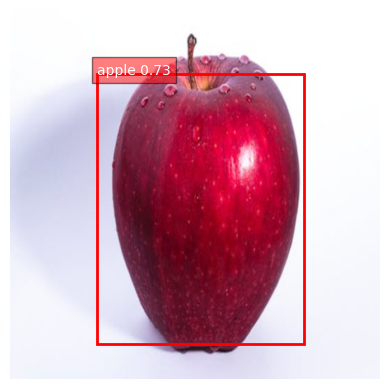

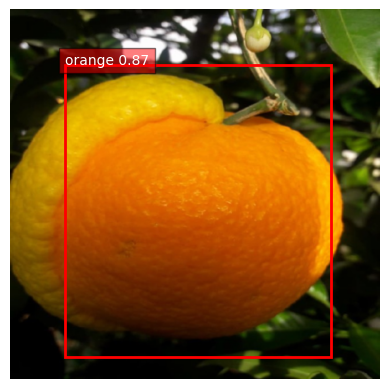

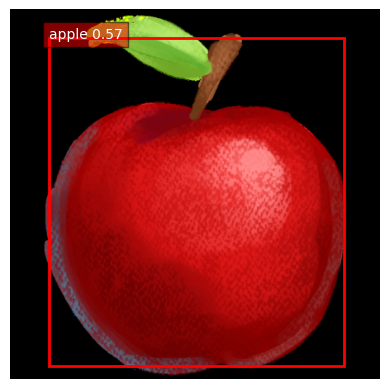

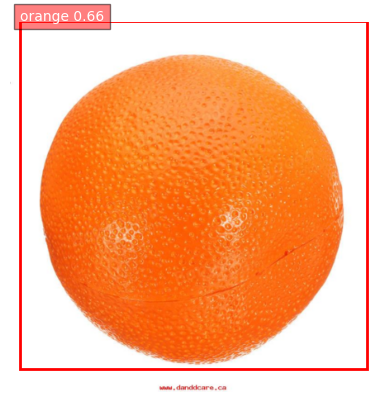

In [ ]:
import torch
import torch.optim as optim
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from torch.utils.data import DataLoader

# -------------------------------
# CONFIG
# -------------------------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 1
IOU_THRESHOLD = 0.5
CONF_THRESHOLD = 0.4

S = 7
B = 2
C = 3

class_labels = ["apple", "banana", "orange"]

# -------------------------------
# IOU FUNCTION
# -------------------------------
def intersection_over_union(boxes_preds, boxes_labels, box_format="midpoint"):
    if box_format == "midpoint":
        box1_x1 = boxes_preds[..., 0] - boxes_preds[..., 2] / 2
        box1_y1 = boxes_preds[..., 1] - boxes_preds[..., 3] / 2
        box1_x2 = boxes_preds[..., 0] + boxes_preds[..., 2] / 2
        box1_y2 = boxes_preds[..., 1] + boxes_preds[..., 3] / 2

        box2_x1 = boxes_labels[..., 0] - boxes_labels[..., 2] / 2
        box2_y1 = boxes_labels[..., 1] - boxes_labels[..., 3] / 2
        box2_x2 = boxes_labels[..., 0] + boxes_labels[..., 2] / 2
        box2_y2 = boxes_labels[..., 1] + boxes_labels[..., 3] / 2

    x1 = torch.max(box1_x1, box2_x1)
    y1 = torch.max(box1_y1, box2_y1)
    x2 = torch.min(box1_x2, box2_x2)
    y2 = torch.min(box1_y2, box2_y2)

    intersection = (x2 - x1).clamp(0) * (y2 - y1).clamp(0)

    box1_area = abs((box1_x2 - box1_x1) * (box1_y2 - box1_y1))
    box2_area = abs((box2_x2 - box2_x1) * (box2_y2 - box2_y1))

    return intersection / (box1_area + box2_area - intersection + 1e-6)

# -------------------------------
# NON-MAX SUPPRESSION
# -------------------------------
def non_max_suppression(bboxes, iou_threshold, threshold):
    bboxes = [box for box in bboxes if box[1] > threshold]
    bboxes = sorted(bboxes, key=lambda x: x[1], reverse=True)

    result = []

    while bboxes:
        chosen_box = bboxes.pop(0)

        bboxes = [
            box
            for box in bboxes
            if box[0] != chosen_box[0]
            or intersection_over_union(
                torch.tensor(chosen_box[2:]),
                torch.tensor(box[2:])
            ) < iou_threshold
        ]

        result.append(chosen_box)

    return result

# -------------------------------
# CONVERT YOLO OUTPUT → BOXES
# -------------------------------
def cellboxes_to_boxes(out):
    out = out.reshape(out.shape[0], S, S, C + B * 5)

    bboxes1 = out[..., C+1:C+5]
    bboxes2 = out[..., C+6:C+10]

    scores = torch.cat(
        (out[..., C].unsqueeze(0), out[..., C+5].unsqueeze(0)), dim=0
    )

    best_box = scores.argmax(0).unsqueeze(-1)
    best_boxes = bboxes1 * (1 - best_box) + best_box * bboxes2

    cell_indices = torch.arange(S).repeat(S, 1).unsqueeze(-1).to(out.device)

    x = (best_boxes[..., 0:1] + cell_indices) / S
    y = (best_boxes[..., 1:2] + cell_indices.permute(1, 0, 2)) / S
    w = best_boxes[..., 2:3] / S
    h = best_boxes[..., 3:4] / S

    converted = torch.cat((x, y, w, h), dim=-1)

    predicted_class = out[..., :C].argmax(-1).unsqueeze(-1)
    best_conf = torch.max(out[..., C], out[..., C+5]).unsqueeze(-1)

    return torch.cat((predicted_class, best_conf, converted), dim=-1).reshape(out.shape[0], -1, 6)

# -------------------------------
# PLOT IMAGE WITH BOXES
# -------------------------------
def plot_image(image, boxes):
    img = image.permute(1, 2, 0).cpu().numpy()
    h, w, _ = img.shape

    fig, ax = plt.subplots(1)
    ax.imshow(img)

    for box in boxes:
        # Ensure all tensor elements are converted to Python scalars for plotting
        cls_tensor, conf_tensor, x_tensor, y_tensor, bw_tensor, bh_tensor = box

        cls = int(cls_tensor.item())
        conf = conf_tensor.item()
        x = x_tensor.item()
        y = y_tensor.item()
        bw = bw_tensor.item()
        bh = bh_tensor.item()

        x1 = (x - bw / 2) * w
        y1 = (y - bh / 2) * h

        rect = patches.Rectangle(
            (x1, y1),
            bw * w,
            bh * h,
            linewidth=2,
            edgecolor='red',
            facecolor='none'
        )
        ax.add_patch(rect)

        label = f"{class_labels[cls]} {conf:.2f}"
        ax.text(
            x1, y1,
            label,
            color="white",
            bbox=dict(facecolor="red", alpha=0.5)
        )

    plt.axis("off")
    plt.show()

# -------------------------------
# MAIN VISUALIZATION FUNCTION
# -------------------------------
def visualize_predictions():
    model = YoloV1(split_size=7, num_boxes=2, num_classes=3).to(DEVICE)

    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    load_checkpoint(torch.load(LOAD_MODEL_FILE), model, optimizer)

    test_dataset = FruitImagesDataset(
        transform=transform,
        df=test_df,
        files_dir=test_dir
    )

    loader = DataLoader(test_dataset, batch_size=1, shuffle=True)

    model.eval()

    for idx, (x, y) in enumerate(loader):
        x = x.to(DEVICE)

        with torch.no_grad():
            preds = model(x)

        bboxes = cellboxes_to_boxes(preds)

        bboxes = non_max_suppression(
            bboxes[0],
            iou_threshold=IOU_THRESHOLD,
            threshold=CONF_THRESHOLD
        )

        plot_image(x[0], bboxes)

        if idx == 10:  # show 5 images
            break

# -------------------------------
# RUN
# -------------------------------
visualize_predictions()